# Mixture of Experts and Routing: Theory Notebook

This notebook turns MoE routing into concrete arrays: router probabilities, top-k dispatch, capacity overflow, auxiliary balancing, active parameter counts, all-to-all traffic, and collapse diagnostics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Router probabilities and top-k experts

In [2]:
def softmax(z, axis=-1):
    z = np.asarray(z, dtype=float)
    z = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

router_logits = np.array([
    [2.0, 0.5, -0.3, 1.2],
    [0.1, 2.2, 1.8, -0.4],
    [1.0, 1.1, 1.2, 1.3],
])
probs = softmax(router_logits, axis=1)
k = 2
topk = np.argsort(probs, axis=1)[:, -k:][:, ::-1]
print("router probabilities:\n", np.round(probs, 3))
print("top-k experts:\n", topk)

router probabilities:
 [[0.564 0.126 0.057 0.253]
 [0.066 0.536 0.359 0.04 ]
 [0.214 0.236 0.261 0.289]]
top-k experts:
 [[0 3]
 [1 2]
 [3 2]]


## 2. Top-k gated combination

In [3]:
rng = np.random.default_rng(4)
tokens, experts, d = 3, 4, 5
x = rng.normal(size=(tokens, d))
expert_outputs = rng.normal(size=(tokens, experts, d))
weights = np.zeros((tokens, experts))
for t in range(tokens):
    selected = topk[t]
    w = probs[t, selected]
    weights[t, selected] = w / w.sum()
y = np.einsum("te,ted->td", weights, expert_outputs)
print("routing weights:\n", np.round(weights, 3))
print("combined output shape:", y.shape)

routing weights:
 [[0.69  0.    0.    0.31 ]
 [0.    0.599 0.401 0.   ]
 [0.    0.    0.475 0.525]]
combined output shape: (3, 5)


## 3. Parameter accounting

In [4]:
d_model = 4096
d_ff = 4 * d_model
experts = 8
k = 2
dense_ffn = 2 * d_model * d_ff
total_expert = experts * dense_ffn
active_expert = k * dense_ffn
router = d_model * experts
print("dense FFN params:", f"{dense_ffn:,}")
print("total expert params:", f"{total_expert:,}")
print("active expert params per token:", f"{active_expert:,}")
print("router params:", f"{router:,}")

dense FFN params: 134,217,728
total expert params: 1,073,741,824
active expert params per token: 268,435,456
router params: 32,768


## 4. Capacity and overflow

In [5]:
assignments = np.array([0, 0, 0, 1, 1, 2, 3, 3, 3, 3])
tokens = len(assignments)
experts = 4
capacity_factor = 1.25
capacity = int(np.ceil(capacity_factor * tokens / experts))
loads = np.bincount(assignments, minlength=experts)
overflow = np.maximum(0, loads - capacity)
print("capacity per expert:", capacity)
print("loads:", loads)
print("overflow:", overflow)
print("drop rate:", overflow.sum() / tokens)

capacity per expert: 4
loads: [3 2 1 4]
overflow: [0 0 0 0]
drop rate: 0.0


## 5. Expert histogram

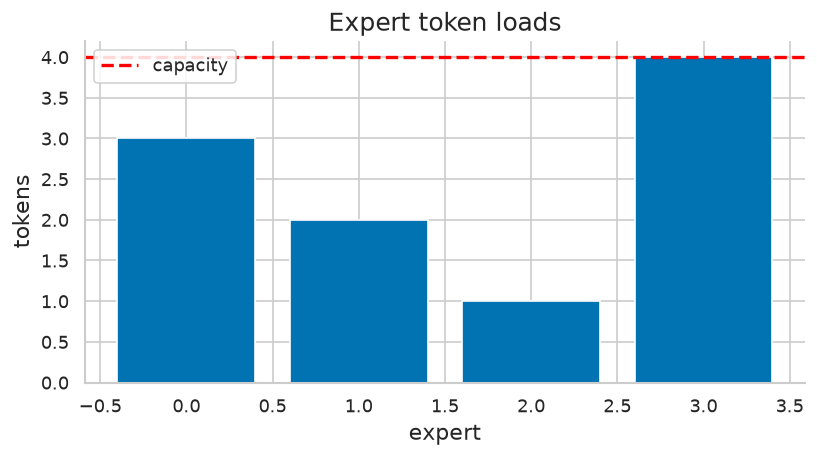

max/min load ratio: 4.0


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(experts), loads)
ax.axhline(capacity, color="red", linestyle="--", label="capacity")
ax.set_title("Expert token loads")
ax.set_xlabel("expert")
ax.set_ylabel("tokens")
ax.legend()
fig.tight_layout()
plt.show()
print("max/min load ratio:", loads.max() / max(1, loads.min()))

## 6. Switch-style auxiliary loss proxy

In [7]:
router_probs = probs
top1 = np.argmax(router_probs, axis=1)
f = np.bincount(top1, minlength=router_probs.shape[1]) / router_probs.shape[0]
P = router_probs.mean(axis=0)
aux = router_probs.shape[1] * np.sum(f * P)
print("fraction routed f:", np.round(f, 3))
print("mean probability P:", np.round(P, 3))
print("aux loss proxy:", round(aux, 4))

fraction routed f: [0.333 0.333 0.    0.333]
mean probability P: [0.281 0.299 0.226 0.194]
aux loss proxy: 1.0325


## 7. Router entropy

In [8]:
entropy = -np.sum(probs * np.log(probs + 1e-12), axis=1)
for t, h in enumerate(entropy):
    print(f"token {t}: entropy={h:.3f}")
print("max entropy for 4 experts:", np.log(4))

token 0: entropy=1.094
token 1: entropy=1.009
token 2: entropy=1.380
max entropy for 4 experts: 1.3862943611198906


## 8. Z-loss proxy

In [9]:
lse = np.log(np.exp(router_logits).sum(axis=1))
z_loss = np.mean(lse**2)
print("log-sum-exp values:", np.round(lse, 3))
print("z-loss proxy:", round(z_loss, 4))

log-sum-exp values: [2.573 2.824 2.543]
z-loss proxy: 7.0198


## 9. All-to-all traffic toy

In [10]:
expert_to_rank = np.array([0, 0, 1, 1])
token_origin_rank = np.array([0, 0, 0, 1, 1, 1])
token_expert = np.array([0, 2, 3, 1, 2, 3])
dest_rank = expert_to_rank[token_expert]
cross = token_origin_rank != dest_rank
print("destination ranks:", dest_rank)
print("cross-rank tokens:", cross.sum(), "of", len(cross))

destination ranks: [0 1 1 0 1 1]
cross-rank tokens: 3 of 6


## 10. Router collapse simulation

In [11]:
rng = np.random.default_rng(0)
balanced = rng.choice(8, size=512, p=np.ones(8) / 8)
collapsed = rng.choice(8, size=512, p=np.array([0.55, 0.25, 0.10, 0.04, 0.03, 0.02, 0.005, 0.005]))
for name, arr in [("balanced", balanced), ("collapsed", collapsed)]:
    loads = np.bincount(arr, minlength=8)
    print(name, "loads", loads, "max/min", loads.max() / max(1, loads.min()))

balanced loads [58 57 49 64 76 63 68 77] max/min 1.5714285714285714
collapsed loads [278 139  58  18   8   7   2   2] max/min 139.0


## 11. Top-1 versus top-2 active compute

In [12]:
experts = 16
dense_ffn_flops = 1.0
for k in [1, 2, 4]:
    active = k * dense_ffn_flops
    total_capacity = experts * dense_ffn_flops
    print(f"top-{k}: active FFN compute={active:.1f}x dense, total expert capacity={total_capacity:.1f}x")

top-1: active FFN compute=1.0x dense, total expert capacity=16.0x
top-2: active FFN compute=2.0x dense, total expert capacity=16.0x
top-4: active FFN compute=4.0x dense, total expert capacity=16.0x


## 12. Final MoE checklist

In [13]:
checks = [
    "log total parameters and active parameters separately",
    "plot expert load histogram",
    "track drop rate and capacity factor",
    "track router entropy and z-loss",
    "measure all-to-all traffic and expert compute time",
    "compare top-1, top-2, and dense baselines",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. log total parameters and active parameters separately
2. plot expert load histogram
3. track drop rate and capacity factor
4. track router entropy and z-loss
5. measure all-to-all traffic and expert compute time
6. compare top-1, top-2, and dense baselines


## New demo: Top-k gating renormalization (new, notes 11.1)

In [14]:
scores=np.array([2.0,1.0,0.5,0.0,-1.0]); e=np.exp(scores-scores.max()); P=e/e.sum(); k=2; idx=np.argsort(-P)[:k]; tilde=np.zeros_like(P); tilde[idx]=P[idx]/P[idx].sum()
print("P:",np.round(P,3),"topk renormalized:",np.round(tilde,3))
print(f"{'PASS' if abs(tilde.sum()-1)<1e-12 else 'FAIL'} - top-k weights renormalize to one")

P: [0.563 0.207 0.126 0.076 0.028] topk renormalized: [0.731 0.269 0.    0.    0.   ]
PASS - top-k weights renormalize to one


## New demo: Load-balancing loss: uniform versus collapsed (new, notes 11.2/16.2)

In [15]:
def aux(f): 
    f=np.asarray(f,float); return len(f)*float(np.sum(f*f))
uni=np.full(8,1/8); col=np.array([1.0]+[0.0]*7)
print(f"uniform aux={aux(uni):.3f}, collapsed aux={aux(col):.3f}, ratio={aux(col)/aux(uni):.0f}x")
print(f"{'PASS' if aux(col)>aux(uni) else 'FAIL'} - collapsed routing pays a larger balancing loss")

uniform aux=1.000, collapsed aux=8.000, ratio=8x
PASS - collapsed routing pays a larger balancing loss


## New demo: Simulated router histogram, entropy, hottest share (new, notes 20/32)

histogram: [0.128 0.128 0.13  0.13  0.113 0.124 0.124 0.126]
entropy=2.079 (max ln8=2.079), hottest=1.04x mean


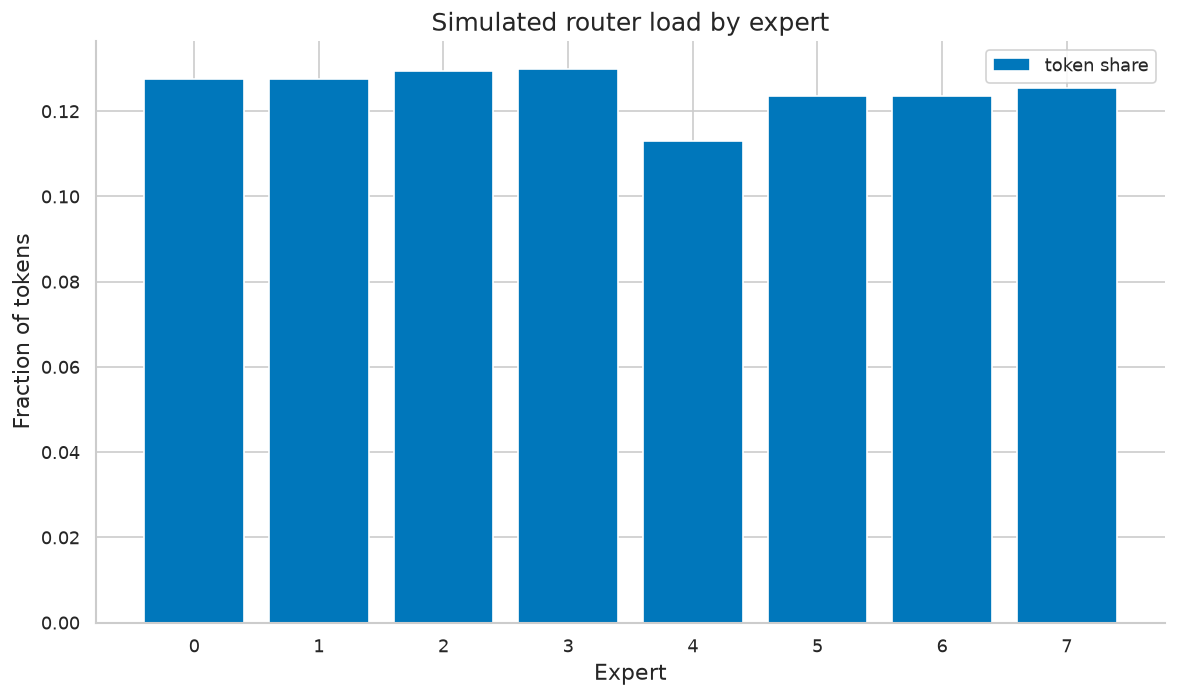

PASS - simulated routing entropy is below the uniform ceiling


In [16]:
rng=np.random.default_rng(42); logits=rng.normal(0,1.5,size=(2000,8)); choice=np.argmax(logits,axis=1); hist=np.bincount(choice,minlength=8)/len(choice)
ent=float(-(hist*np.log(hist)).sum()); hot=float(hist.max()/(1/8))
print("histogram:",np.round(hist,3)); print(f"entropy={ent:.3f} (max ln8={np.log(8):.3f}), hottest={hot:.2f}x mean")
fig, ax = plt.subplots(); ax.bar([str(i) for i in range(8)], hist, color="#0077BB", label="token share")
ax.set_title("Simulated router load by expert"); ax.set_xlabel("Expert"); ax.set_ylabel("Fraction of tokens"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print(f"{'PASS' if ent<np.log(8) else 'FAIL'} - simulated routing entropy is below the uniform ceiling")

## New demo: Capacity and token dropping (new, notes 11.3)

In [17]:
toks=8192; E=8; Cf=1.0; cap=int(Cf*toks/E); arrivals=np.array([1500,1100,1024,900,1000,950,900,818]); drops=np.maximum(arrivals-cap,0)
print(f"capacity/expert={cap}, drops per expert={drops}, total dropped={drops.sum()} ({100*drops.sum()/arrivals.sum():.1f}%)")
print(f"{'PASS' if drops[0]==476 else 'FAIL'} - overflow arithmetic matches the notes example")

capacity/expert=1024, drops per expert=[476  76   0   0   0   0   0   0], total dropped=552 (6.7%)
PASS - overflow arithmetic matches the notes example


## New demo: Total versus active parameters (new, notes 26.2)

In [18]:
S=2e9; We=0.5e9
for E,k in [(8,2),(64,2),(64,6)]:
    print(f"E={E},k={k}: total={(S+E*We)/1e9:.1f}B active={(S+k*We)/1e9:.1f}B")
print(f"{'PASS' if (S+64*We)>(S+2*We) else 'FAIL'} - total grows with E while active follows k")

E=8,k=2: total=6.0B active=3.0B
E=64,k=2: total=34.0B active=3.0B
E=64,k=6: total=34.0B active=5.0B
PASS - total grows with E while active follows k


## New demo: Dispatch traffic (new, notes 25.2)

In [19]:
for toks,k,h in [(8192,2,4096),(65536,2,8192)]:
    gb=toks*k*h*2/1e9; print(f"tokens={toks},k={k},h={h}: dispatch {gb:.2f} GB, round trip {2*gb:.2f} GB")
print(f"{'PASS' if abs(8192*2*4096*2/1e9-0.134)<0.001 else 'FAIL'} - dispatch traffic arithmetic")

tokens=8192,k=2,h=4096: dispatch 0.13 GB, round trip 0.27 GB
tokens=65536,k=2,h=8192: dispatch 2.15 GB, round trip 4.29 GB
PASS - dispatch traffic arithmetic


## New demo: Router z-loss grows with logit scale (new, notes 12.1)

In [20]:
for scale in [1.0,3.0,6.0]:
    g=np.array([scale,0.0,-scale]); z=float(np.log(np.exp(g).sum())**2); print(f"logit scale {scale}: z-loss term {z:.2f}")
g1=np.log(np.exp(np.array([1.0,0,-1.0])).sum())**2; g6=np.log(np.exp(np.array([6.0,0,-6.0])).sum())**2
print(f"{'PASS' if g6>g1 else 'FAIL'} - z-loss penalizes large router logits")

logit scale 1.0: z-loss term 1.98
logit scale 3.0: z-loss term 9.31
logit scale 6.0: z-loss term 36.03
PASS - z-loss penalizes large router logits


## New demo: Dead expert has no gradient path (new, notes 12.3)

In [21]:
hist=np.array([0.4,0.3,0.3,0.0]); grad_proxy=hist*2.0
print("gradient proxy per expert:",grad_proxy)
print(f"{'PASS' if grad_proxy[3]==0 else 'FAIL'} - an expert with no tokens receives no routed gradient")

gradient proxy per expert: [0.8 0.6 0.6 0. ]
PASS - an expert with no tokens receives no routed gradient


## New demo: Shared expert accounting (new, notes 14.1)

In [22]:
shared=0.3e9; routed_active=2*0.5e9; total_active=shared+routed_active
print(f"active with shared expert: {total_active/1e9:.1f}B (shared runs for every token)")
print(f"{'PASS' if total_active==1.3e9 else 'FAIL'} - shared expert adds to every token's active count")

active with shared expert: 1.3B (shared runs for every token)
PASS - shared expert adds to every token's active count


## New demo: Mixtral-style active fraction (new, notes 11.5)

In [23]:
E,k=8,2; print(f"routed-expert active fraction: {k/E:.0%}")
print(f"{'PASS' if k/E==0.25 else 'FAIL'} - top-2 of 8 activates one quarter of routed experts")

routed-expert active fraction: 25%
PASS - top-2 of 8 activates one quarter of routed experts


## New demo: Expert-choice coverage contrast (new, notes 57)

In [24]:
# token-choice: every token gets exactly k experts; expert-choice: coverage varies
token_choice=np.full(100,2); expert_choice=np.array([0]*20+[1]*30+[2]*30+[4]*20)
print(f"token-choice coverage mean={token_choice.mean():.1f} (constant), expert-choice mean={expert_choice.mean():.2f} with {100*np.mean(expert_choice==0):.0f}% tokens uncovered")
print(f"{'PASS' if np.mean(expert_choice==0)>0 else 'FAIL'} - expert-choice can leave tokens uncovered")

token-choice coverage mean=2.0 (constant), expert-choice mean=1.70 with 20% tokens uncovered
PASS - expert-choice can leave tokens uncovered


## New demo: Hot expert step factor (new, notes 13/46)

In [25]:
for share,E in [(0.4,8),(0.1,64)]:
    print(f"hottest share {share} over E={E}: {share/(1/E):.1f}x mean load")
print(f"{'PASS' if abs(0.4/(1/8)-3.2)<1e-9 else 'FAIL'} - hot expert carries 3.2x mean work")

hottest share 0.4 over E=8: 3.2x mean load
hottest share 0.1 over E=64: 6.4x mean load
PASS - hot expert carries 3.2x mean work
